In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [34]:
import pandas as pd
import sklearn
import numpy as np
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt

# 1) Análise de Dados

In [ ]:
# Busca do Dataset
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

In [42]:
df_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_iot2022.shape}')
print(f'Target: {target_column}\n')

df_iot2022.head(5)

Shape: (123117, 84)
Target: Attack_type



,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,...,0.0,29729182.96,29729182.96,29729182.96,29729182.96,0.0,64240,26847,502,MQTT_Publish
1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,...,0.0,29855277.06,29855277.06,29855277.06,29855277.06,0.0,64240,26847,502,MQTT_Publish
2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,...,0.0,29842149.02,29842149.02,29842149.02,29842149.02,0.0,64240,26847,502,MQTT_Publish
3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,...,0.0,29913774.97,29913774.97,29913774.97,29913774.97,0.0,64240,26847,502,MQTT_Publish
4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,...,0.0,29814704.90,29814704.90,29814704.90,29814704.90,0.0,64240,26847,502,MQTT_Publish


In [27]:
# Recuperação das colunas numéricas
numeric_columns = df_iot2022.select_dtypes(include=np.number).columns.to_list()
print(len(numeric_columns))

81


In [22]:
# Verificação de Linhas Duplicadas
print(f'Linhas Duplicadas: {df_iot2022.duplicated().sum()}')
print(f'% Duplicadas: {df_iot2022.duplicated().mean() * 100:.2f}\n')

null_values = df_iot2022.isnull().sum()
percent = round(null_values/len(df_iot2022) * 100, 2)

df_null_values = pd.DataFrame({"nulos": null_values, "(%)": percent}).sort_values(by='nulos', ascending=False)

print(df_null_values[df_null_values['nulos'] > 0] if (null_values > 0).any() else 'Sem Valores Nulos')

Linhas Duplicadas: 5195
% Duplicadas: 4.22

Sem Valores Nulos


Identificação de Outliers

In [28]:
def outlier_detection(pd_series: pd.Series):
    """ 
    Detecção de Outliers através da diferença entre o terceiro e o primeiro qquartil 
    """
    Q1 = pd_series.quantile(0.25)
    Q3 = pd_series.quantile(0.75)
    IQR = Q3 - Q1 

    lower_limit = Q1 - (1.5 * IQR)
    upper_limit = Q3 + (1.5 * IQR) 

    return  int(((pd_series < lower_limit) | (pd_series > upper_limit)).sum())

In [35]:
outlier_iqr = df_iot2022[numeric_columns].apply(outlier_detection).sort_values(ascending=False)
percent_iqr = round(outlier_iqr/len(df_iot2022) * 100, 2)

df_outliers = pd.DataFrame(data={"qtd_outliers": outlier_iqr, "pct_outliers": percent_iqr})
print(df_outliers)

                          qtd_outliers  pct_outliers
flow_pkts_payload.avg            38116         30.96
bwd_header_size_tot              33148         26.92
bwd_header_size_max              33137         26.92
flow_ACK_flag_count              33083         26.87
bwd_pkts_tot                     32364         26.29
...                                ...           ...
id.orig_p                            0          0.00
flow_pkts_per_sec                    0          0.00
bwd_pkts_per_sec                     0          0.00
bwd_URG_flag_count                   0          0.00
payload_bytes_per_second             0          0.00

[81 rows x 2 columns]


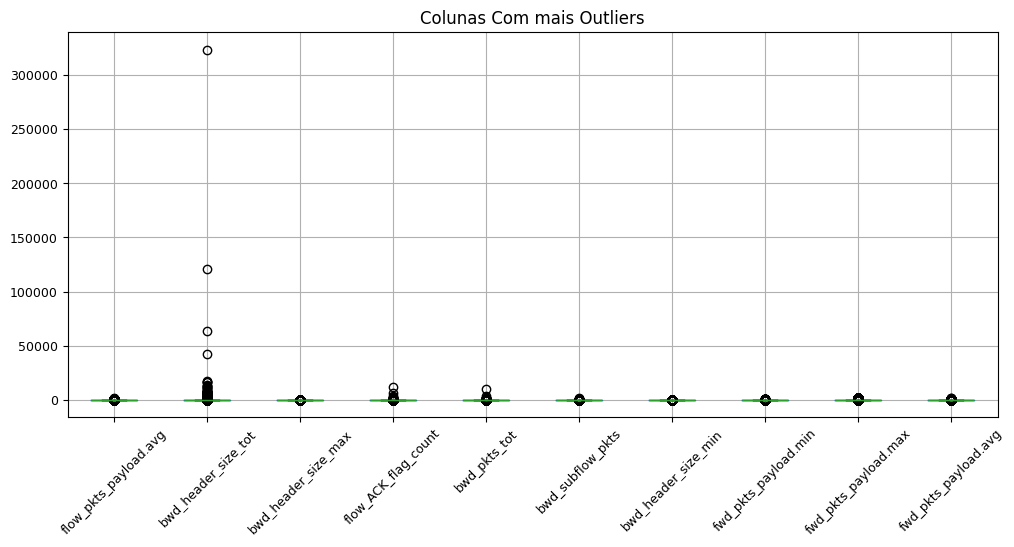

In [41]:
top_10_outliers = df_outliers.head(10).index

df_iot2022[top_10_outliers].boxplot(figsize=(12, 5), rot=45, fontsize=9)
plt.title("Colunas Com mais Outliers")
plt.show()

Distribuição das Classes

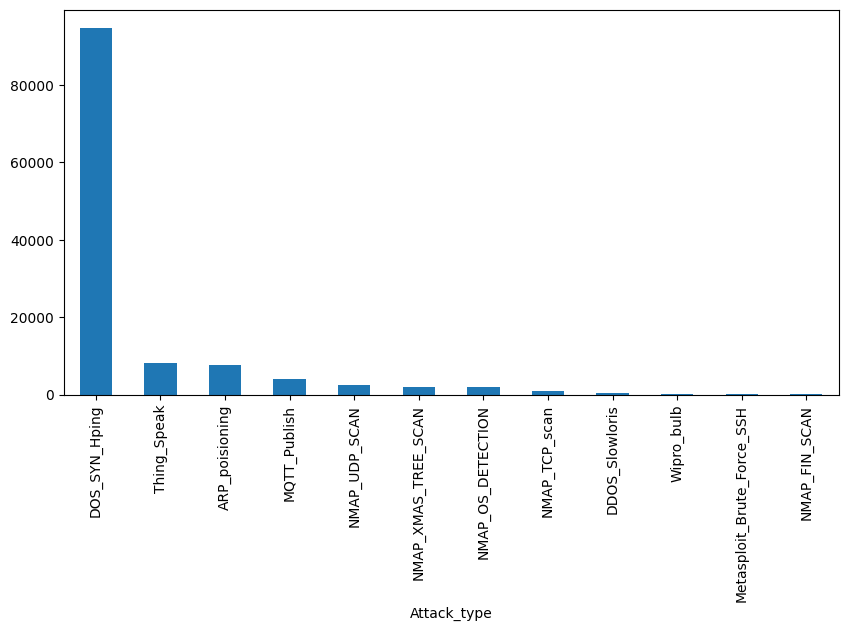

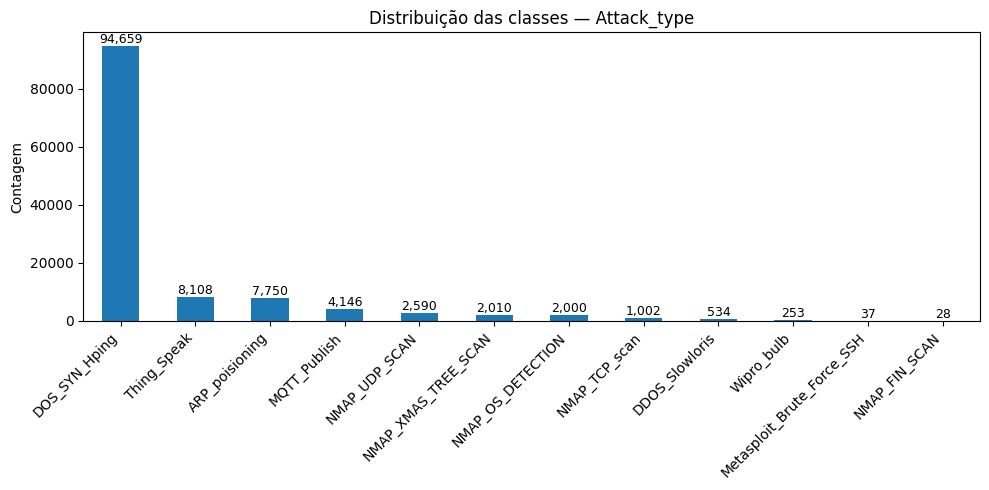

In [ ]:
df_volumetry = df_iot2022[target_column].value_counts()
df_percent = round(df_iot2022[target_column].value_counts(normalize=True) * 100, 2)

fig, axes = plt.subplots(figsize=(10, 5))
df_volumetry.plot(kind='bar', ax=axes)

axes.set_title(f'Distribuição das classes — {target_column}')
axes.set_ylabel('Contagem')
axes.set_xlabel('')

for i, v in enumerate(df_volumetry.values):
    axes.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [48]:
# Descrição das Colunas Numericas

df_iot2022[numeric_columns].describe()

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,65535.000000,65389.000000,21728.335580,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


# 2) Correlação com as outras colunas

com o AttackType é multiclasse